In [1]:
# np — численные массивы; sp — формулы; plt — графики; SciPy — интегралы и уравнения.
import numpy as np
import re
import sympy as sp
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.patches import Circle
from scipy.integrate import solve_ivp, quad
from scipy.optimize import brentq
from scipy.special import ellipj, ellipk
from IPython.display import display, HTML
# Ускорение свободного падения, м/с²; далее используем метры и секунды.
g=9.81
# Кадры анимаций сохраняем в JPEG с dpi 60, чтобы ноутбук не был слишком тяжёлым.
plt.rcParams.update({'figure.dpi':85,'axes.grid':True,'grid.alpha':.25,'animation.embed_limit':80,
                     'animation.frame_format':'jpeg','savefig.dpi':60})
# Число кадров анимации; FPS — сколько кадров показывать за секунду.
FRAMES=64
FPS=16

# Показываем рисунок в ноутбуке.
def finish(fig):
    fig.tight_layout()
    plt.show()
    plt.close(fig)
def movie(fig,update,frames=FRAMES):
    # FuncAnimation вызывает update(k) для каждого кадра k.
    animation=FuncAnimation(fig,update,frames=frames,interval=1000/FPS,blit=False)
    # to_jshtml упаковывает кадры и кнопки воспроизведения в автономную анимацию.
    html=animation.to_jshtml(fps=FPS,default_mode='once')
    # Убираем сетевой шрифт и заменяем иконки обычными символами: HTML работает офлайн.
    html=re.sub(r'<link[^>]*>', '', html)
    icons={'fa-minus':'−','fa-fast-backward':'⏮','fa-step-backward':'◀|',
           'fa-play fa-flip-horizontal':'◀','fa-pause':'Ⅱ','fa-play':'▶',
           'fa-step-forward':'|▶','fa-fast-forward':'⏭','fa-plus':'+'}
    for klass,symbol in icons.items():
        html=html.replace('<i class="fa '+klass+'"></i>',symbol)
    for en,ru in [('Decrease speed','Медленнее'),('Increase speed','Быстрее'),('First frame','В начало'),
                  ('Last frame','В конец'),('Previous frame','Предыдущий кадр'),('Next frame','Следующий кадр'),
                  ('Play backwards','Назад'),('Pause','Пауза'),('Play','Воспроизвести')]:
        html=html.replace('"'+en+'"','"'+ru+'"')
    plt.close(fig)
    display(HTML(html))
    return html

# allclose проверяет приближённое равенство всех элементов; atol и rtol — допуски ошибки.
def check_close(a,b,atol=1e-8):
    assert np.allclose(a,b,atol=atol,rtol=1e-8)

## 3.1. Кривая равномерного вертикального спуска

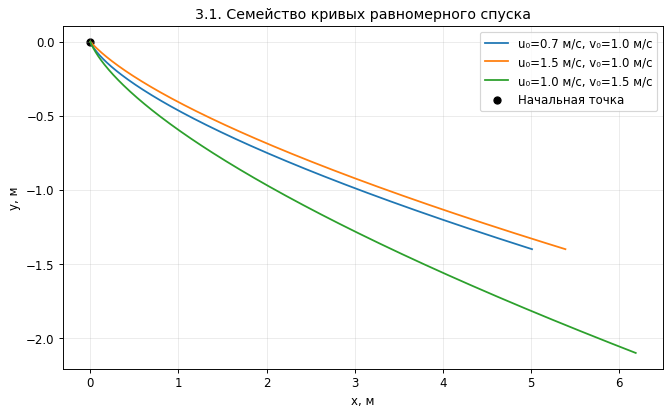

In [ ]:
# Аналитическое решение: u — горизонтальная скорость, вертикальная скорость равна −v0.
def descent(t,u0=1.,v0=1.,x0=0.,y0=0.):
    # asarray позволяет считать формулы сразу для всего массива моментов времени.
    t=np.asarray(t)
    u=np.sqrt(u0*u0+2*g*v0*t)
    x=x0+(u**3-u0**3)/(3*g*v0)
    y=y0-v0*t
    return x,y,u
# Символьные переменные нужны для проверки формул без численного округления.
u0s,v0s,gs,ts=sp.symbols('u0 v0 g t',positive=True)
us=sp.sqrt(u0s**2+2*gs*v0s*ts)
xs=(us**3-u0s**3)/(3*gs*v0s)
ys=-v0s*ts
# diff берёт производную; проверяем скорость и уравнение движения.
assert sp.simplify(sp.diff(xs,ts)-us)==0 # type: ignore
assert sp.simplify(us*sp.diff(us,ts)-gs*v0s)==0 # type: ignore
assert sp.diff(ys,ts)==-v0s
# linspace задаёт равномерную сетку времени; сравниваем три начальные скорости.
fig,ax=plt.subplots(figsize=(8,5))
tt=np.linspace(0,1.4,300)
for u0,v0 in [(0.7,1.),(1.5,1.),(1.,1.5)]:
    xx,yy,uu=descent(tt,u0,v0)
    ax.plot(xx,yy,label=f'u₀={u0} м/с, v₀={v0} м/с')
    # Проверяем сохранение энергии на единицу массы: (u²+v₀²)/2 + gy = const.
    check_close(.5*(uu**2+v0**2)+g*yy,.5*(u0**2+v0**2))
    check_close(yy,(u0*u0-(u0**3+3*g*v0*xx)**(2/3))/(2*g))
ax.scatter([0],[0],color='black',label='Начальная точка')
ax.set(xlabel='x, м',ylabel='y, м',title='3.1. Семейство кривых равномерного спуска')
ax.legend()
finish(fig)

In [3]:
# Считаем положения тела для всех кадров заранее.
t31=np.linspace(0,1.4,FRAMES)
xx31,yy31,uu31=descent(t31)
fig,ax=plt.subplots(figsize=(7,4))
ax.plot(xx31,yy31,color='#4079a8')
# Создаём точку и подпись; запятая извлекает единственную линию из списка plot.
point,=ax.plot([],[],'o',color='#c74336',ms=9)
label=ax.text(.03,.93,'',transform=ax.transAxes,va='top')
ax.set(xlabel='x, м',ylabel='y, м',title='3.1. Вертикальная скорость постоянна')
fig.tight_layout()
# k — номер кадра; set_data перемещает точку, set_text обновляет подпись.
def update31(k):
    point.set_data([xx31[k]],[yy31[k]])
    label.set_text(f't={t31[k]:.2f} с; y={yy31[k]:.2f} м\nvᵧ=−1.00 м/с; vₓ={uu31[k]:.2f} м/с')
movie31=movie(fig,update31)

## 3.2. Бильярд в прямоугольнике

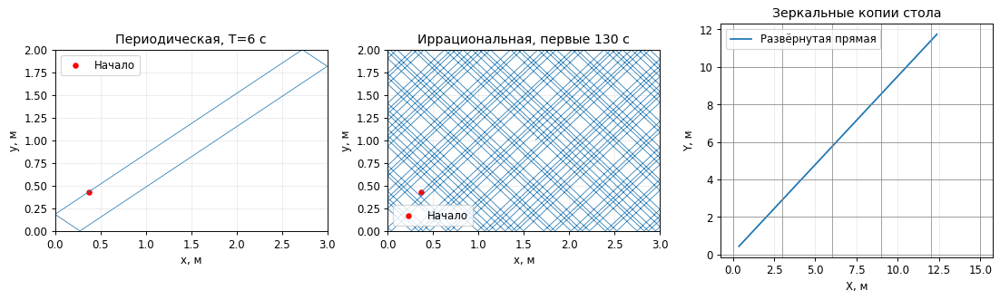

In [4]:
# Задаём стороны стола, начальную точку и горизонтальную скорость.
a,b=3.,2.
x0,y0=.37,.43
vx=1.
# Сравниваем рациональное и иррациональное отношения периодов движения по осям.
vy_cases=[2/3,(2/3)*np.sqrt(2)]
# mod берёт остаток; «складываем» прямую траекторию обратно в отрезок с отражениями.
def fold(s,L):
    return L-np.abs(np.mod(s,2*L)-L)
def billiard(t,vy):
    return fold(x0+vx*np.asarray(t),a),fold(y0+vy*np.asarray(t),b)
# Две периодические координаты превращаем в углы на торе (поверхности бублика).
def torus(t,vy):
    p=2*np.pi*(x0+vx*np.asarray(t))/(2*a)
    q=2*np.pi*(y0+vy*np.asarray(t))/(2*b)
    return np.array([(2+.6*np.cos(q))*np.cos(p),(2+.6*np.cos(q))*np.sin(p),.6*np.sin(q)])
# Для первого направления проверяем возвращение в начальную точку через 6 секунд.
check_close(billiard(0,vy_cases[0]),billiard(6,vy_cases[0]))
# Проверка отражения на одной стенке: нормальная скорость меняет знак, её модуль сохраняется.
eps=1e-6
hit=(a-x0)/vx
left=(fold(x0+vx*hit,a)-fold(x0+vx*(hit-eps),a))/eps
right=(fold(x0+vx*(hit+eps),a)-fold(x0+vx*hit,a))/eps
check_close(left,vx)
check_close(right,-vx)
fig,axes=plt.subplots(1,3,figsize=(13,4))
for ax,vy,end,title in zip(axes[:2],vy_cases,[6,130],['Периодическая, T=6 с','Иррациональная, первые 130 с']):
    t=np.linspace(0,end,int(end*120))
    xx,yy=billiard(t,vy)
    assert np.all((xx>=0)&(xx<=a)&(yy>=0)&(yy<=b))
    ax.plot(xx,yy,lw=.65)
    ax.scatter([x0],[y0],color='red',s=20,label='Начало')
    ax.set(xlim=(0,a),ylim=(0,b),xlabel='x, м',ylabel='y, м',title=title)
    ax.set_aspect('equal')
    ax.legend()
t=np.linspace(0,12,300)
vy=vy_cases[1]
ax=axes[2]
# На развёртке вместо отражений тело идёт по прямой через зеркальные копии стола.
ax.plot(x0+vx*t,y0+vy*t,label='Развёрнутая прямая')
for k in range(6):
    ax.axvline(k*a,color='gray',lw=.6)
    ax.axhline(k*b,color='gray',lw=.6)
ax.set(xlabel='X, м',ylabel='Y, м',title='Зеркальные копии стола')
ax.legend()
finish(fig)

In [ ]:
t32=np.linspace(0,12,FRAMES)
fig=plt.figure(figsize=(12,7))
artists=[]
# Для каждого направления готовим три вида: стол, развёртка и тор.
for row,vy in enumerate(vy_cases):
    title='Рациональное направление' if row==0 else 'Иррациональное направление'
    ax=fig.add_subplot(2,3,3*row+1)
    ax.set(xlim=(0,a),ylim=(0,b),xlabel='x',ylabel='y',title=title)
    ax.set_aspect('equal')
    line,=ax.plot([],[],lw=1)
    point,=ax.plot([],[],'ro',ms=5)
    lab=ax.text(.02,.98,'',transform=ax.transAxes,va='top',fontsize=8)
    axu=fig.add_subplot(2,3,3*row+2)
    axu.set(xlim=(0,13),ylim=(0,13),title='Развёртка',xlabel='X',ylabel='Y')
    for k in range(7):
        axu.axvline(k*a,color='gray',lw=.5)
        axu.axhline(k*b,color='gray',lw=.5)
    lu,=axu.plot([],[],lw=1.4)
    pu,=axu.plot([],[],'ro',ms=5)
    axt=fig.add_subplot(2,3,3*row+3,projection='3d')
    p,q=np.meshgrid(np.linspace(0,2*np.pi,24),np.linspace(0,2*np.pi,14))
    axt.plot_wireframe((2+.6*np.cos(q))*np.cos(p),(2+.6*np.cos(q))*np.sin(p),.6*np.sin(q),alpha=.18,lw=.4) # type: ignore
    lt,=axt.plot([],[],[],color='#b63340',lw=1.2)
    pt,=axt.plot([],[],[],'ro',ms=5)
    axt.set(title='Движение на торе',xlim=(-2.7,2.7),ylim=(-2.7,2.7),zlim=(-.8,.8))
    axt.set_box_aspect([1,1,.4]) # type: ignore
    # Сохраняем ссылки на линии, точки и подписи, чтобы обновлять их в каждом кадре.
    artists.append((vy,line,point,lab,lu,pu,lt,pt))
fig.tight_layout()
def update32(k):
    # Берём частую сетку от начала до текущего времени: она рисует уже пройденный путь.
    dense=np.linspace(0,t32[k],max(2,20*k))
    for vy,line,point,lab,lu,pu,lt,pt in artists:
        # Обновляем путь и точку на столе; [-1] — последняя точка.
        xx,yy=billiard(dense,vy)
        line.set_data(xx,yy)
        point.set_data([xx[-1]],[yy[-1]])
        X=x0+vx*dense
        Y=y0+vy*dense
        lu.set_data(X,Y)
        pu.set_data([X[-1]],[Y[-1]])
        # set_data_3d обновляет пространственные координаты; * распаковывает массивы X, Y, Z.
        xyz=torus(dense,vy)
        lt.set_data_3d(*xyz)
        pt.set_data_3d(*[v[-1:] for v in xyz])
        lab.set_text(f't={t32[k]:.2f} с; |v|={np.hypot(vx,vy):.3f} м/с')
movie32=movie(fig,update32)

## 3.3. Цепная линия

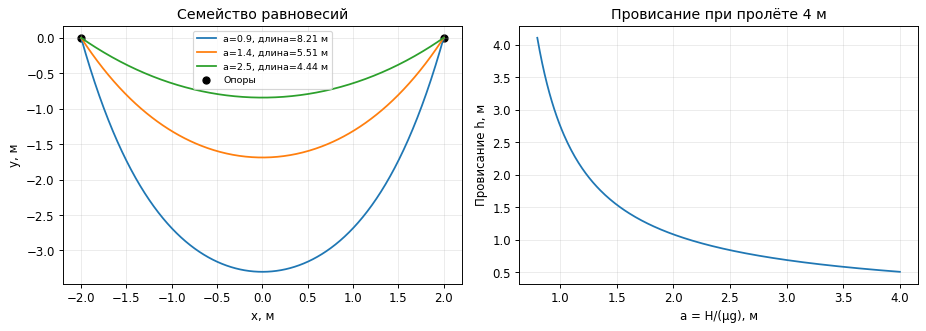

При длине 5.0 м и пролёте 4.0 м: a=1.69100940 м; h=1.32718755 м
μ=0.5 кг/м; H=8.294401 Н; форма та же
μ=1 кг/м; H=16.588802 Н; форма та же
μ=2 кг/м; H=33.177604 Н; форма та же


In [6]:
span=4.
x33=np.linspace(-span/2,span/2,400)
# Цепная линия задаётся cosh (гиперболическим косинусом); вычитание фиксирует высоту опор.
def chain_y(x,a):
    return a*(np.cosh(np.asarray(x)/a)-np.cosh(span/(2*a)))
# sinh — гиперболический синус; формулы дают длину цепи и глубину провисания.
def chain_length(a):
    return 2*a*np.sinh(span/(2*a))
def sag(a):
    return a*(np.cosh(span/(2*a))-1)
asym,xsym=sp.symbols('a x',positive=True)
yexpr=asym*sp.cosh(xsym/asym)
# diff(..., x, 2) — вторая производная; проверяем уравнение цепной линии.
assert sp.simplify(sp.diff(yexpr,xsym,2)-sp.cosh(xsym/asym)/asym)==0
fig,axes=plt.subplots(1,2,figsize=(11,4))
for av in [.9,1.4,2.5]:
    axes[0].plot(x33,chain_y(x33,av),label=f'a={av}, длина={chain_length(av):.2f} м')
    check_close(chain_y(np.array([-span/2,span/2]),av),0)
axes[0].scatter([-2,2],[0,0],color='black',label='Опоры')
axes[0].set(xlabel='x, м',ylabel='y, м',title='Семейство равновесий')
axes[0].legend(fontsize=8)
aa=np.linspace(.8,4,300)
axes[1].plot(aa,sag(aa))
axes[1].set(xlabel='a = H/(μg), м',ylabel='Провисание h, м',title='Провисание при пролёте 4 м')
finish(fig)
length_fixed=5.
# brentq находит корень: подбирает a, при котором длина цепи равна заданным 5 м.
a_fixed=brentq(lambda av:chain_length(av)-length_fixed,.3,20)
print(f'При длине {length_fixed} м и пролёте {span} м: a={a_fixed:.8f} м; h={sag(a_fixed):.8f} м')
for mu in [.5,1,2]:
    print(f'μ={mu} кг/м; H={mu*g*a_fixed:.6f} Н; форма та же')

In [7]:
fig,ax=plt.subplots(figsize=(8,5))
line,=ax.plot([],[],color='#3c719c')
ax.scatter([-2,2],[0,0],color='black')
ax.set(xlim=(-2.7,2.7),ylim=(-3.5,1.1),xlabel='x, м',ylabel='y, м',title='3.3. Семейство статических равновесий')
label=ax.text(.02,.98,'',transform=ax.transAxes,va='top',fontsize=9)
# Создаём три стрелки: натяжение слева, натяжение справа и вес участка.
force_arrows=[]
for color in ['#d47522','#218c69','#b82d48']:
    force_arrows.append(ax.annotate('',xy=(0,0),xytext=(0,0),arrowprops={'arrowstyle':'->','color':color,'lw':2}))
fig.tight_layout()
def update33(k):
    # Первая половина кадров меняет натяжение H, вторая — линейную плотность μ.
    phase=k/(FRAMES-1)
    if phase<=.5:
        mu=1.
        H=g*(.95+1.3*phase)
        stage='μ=1; меняем H'
    else:
        H=1.6*g
        mu=1.+1.4*(phase-.5)
        stage='H=const; меняем μ'
    # Параметр a=H/(μg) определяет форму равновесия; обновляем линию цепи.
    av=H/(mu*g)
    line.set_data(x33,chain_y(x33,av))
    xl,xr=.1,.6
    yl,yr=chain_y(np.array([xl,xr]),av)
    # Считаем векторы натяжения на концах выбранного участка.
    TL=np.array([-H,-H*np.sinh(xl/av)])
    TR=np.array([H,H*np.sinh(xr/av)])
    # Вес равен μg × длина участка и направлен вниз.
    W=np.array([0.,-mu*g*av*(np.sinh(xr/av)-np.sinh(xl/av))])
    # В равновесии сумма сил должна быть нулевой.
    check_close(TL+TR+W,0)
    # Вес приложен к центру масс участка, а не к произвольной точке.
    segment_length=av*(np.sinh(xr/av)-np.sinh(xl/av))
    # quad вычисляет интеграл; cosh(x/a) переводит dx в длину дуги для центра масс.
    xcm=quad(lambda x:x*np.cosh(x/av),xl,xr)[0]/segment_length
    ycm=quad(lambda x:chain_y(x,av)*np.cosh(x/av),xl,xr)[0]/segment_length
    center=np.array([xcm,ycm])
    anchors=[np.array([xl,yl]),np.array([xr,yr]),center]
    # Момент силы на плоскости: xFy−yFx. Суммарный момент в равновесии равен нулю.
    torque=sum(anchor[0]*force[1]-anchor[1]*force[0] for anchor,force in zip(anchors,[TL,TR,W]))
    assert abs(torque)<1e-9
    scale=.025
    # Начало стрелки — точка приложения; конец смещаем пропорционально силе.
    for arrow,anchor,force in zip(force_arrows,anchors,[TL,TR,W]):
        arrow.xy=anchor+scale*force
        arrow.set_position(anchor)
    label.set_text(f'{stage}; μ={mu:.2f} кг/м; H={H:.2f} Н\na={av:.2f} м; h={sag(av):.2f} м; длина={chain_length(av):.2f} м\nОранжевый/зелёный: натяжение; красный: вес')
movie33=movie(fig,update33)

## 3.4. Таутохрона: одинаковое время спуска

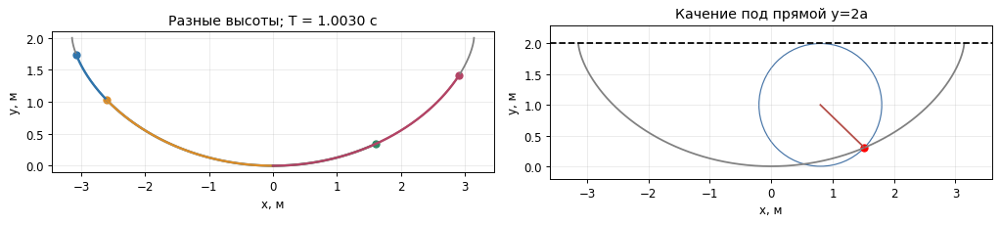

Общее время первого спуска T = 1.003033340355 с


In [8]:
# a — радиус образующей окружности; ω — частота движения по дуге; T — время спуска.
a34=1.
omega34=np.sqrt(g/(4*a34))
T34=np.pi*np.sqrt(a34/g)
# Параметрическое уравнение циклоиды — следа точки катящейся окружности.
def cycloid(u):
    return a34*(np.asarray(u)+np.sin(u)),a34*(1-np.cos(u))
def cycloid_from_s(s):
    # По длине дуги s находим параметр u; clip защищает arcsin от ошибки округления за ±1.
    u=2*np.arcsin(np.clip(np.asarray(s)/(4*a34),-1,1))
    return cycloid(u)
u34=np.linspace(-np.pi,np.pi,600)
xx,yy=cycloid(u34)
# s — длина дуги со знаком от нижней точки; высота пропорциональна s².
signed_s=4*a34*np.sin(u34/2)
check_close(yy,signed_s**2/(8*a34))
# Выбираем четыре начальные точки с разными высотами.
u_starts=np.array([-2.4,-1.6,.85,2.0])
s_starts=4*a34*np.sin(u_starts/2)
# Проверяем исходный интеграл времени с весом h^(-1/2)(H-h)^(-1/2).
for H in [.15,.7,1.7]:
    # quad считает интеграл с особенностями на концах; проверяем одинаковое время для разных высот.
    T_quad=quad(lambda h:np.sqrt(a34/g),0,H,weight='alg',wvar=(-.5,-.5))[0]
    check_close(T_quad,T34)
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].plot(xx,yy,color='gray')
colors=['#2e74ac','#dc8d27','#318865','#b44365']
for us,ss,col in zip(u_starts,s_starts,colors):
    # Рисуем путь от каждой начальной точки до нижней, где s=0.
    path=np.linspace(ss,0,150)
    xp,yp=cycloid_from_s(path)
    axes[0].plot(xp,yp,color=col,lw=2)
    axes[0].scatter(xp[0],yp[0],color=col)
axes[0].set(xlabel='x, м',ylabel='y, м',title=f'Разные высоты; T = {T34:.4f} с')
axes[0].set_aspect('equal')
axes[1].plot(xx,yy,color='gray')
u0=.8
circle=Circle((a34*u0,a34),a34,fill=False,color='#4674a7')
axes[1].add_patch(circle)
xp,yp=cycloid(u0)
axes[1].plot([a34*u0,xp],[a34,yp],color='#b34c46')
axes[1].scatter([xp],[yp],color='red')
axes[1].axhline(2*a34,ls='--',color='black')
axes[1].set(xlabel='x, м',ylabel='y, м',title='Качение под прямой y=2a',xlim=(-3.6,3.6),ylim=(-.2,2.3))
axes[1].set_aspect('equal')
finish(fig)
print(f'Общее время первого спуска T = {T34:.12f} с')

In [9]:
# s(t)=s₀cos(ωt); [:,None] превращает начальные значения в столбец для расчёта всех траекторий.
t34=np.linspace(0,T34,FRAMES)
S34=s_starts[:,None]*np.cos(omega34*t34)[None,:]
# В момент T длина дуги до низа равна нулю у всех шариков.
assert np.max(abs(S34[:,-1]))<1e-12
for initial_s in s_starts:
    # solve_ivp численно решает s′=v, v′=−ω²s; сравниваем с формулой косинуса.
    numeric=solve_ivp(lambda t,q:[q[1],-omega34**2*q[0]],(0,T34),[initial_s,0],t_eval=t34,rtol=1e-10,atol=1e-12)
    assert numeric.success
    check_close(numeric.y[0],initial_s*np.cos(omega34*t34),atol=1e-8)
fig,axes=plt.subplots(1,2,figsize=(11,4.5))
balls=[]
for ax in axes:
    ax.plot(xx,yy,color='#7d8b96')
    ax.set(xlim=(-3.7,3.7),ylim=(-.2,2.4),xlabel='x, м',ylabel='y, м')
    ax.set_aspect('equal')
axes[0].set_title('Одновременный спуск из покоя')
for col in colors:
    ball,=axes[0].plot([],[],'o',ms=8,color=col)
    balls.append(ball)
label=axes[0].text(.02,.95,'',transform=axes[0].transAxes,va='top')
axes[1].set_title('Построение циклоиды качением')
axes[1].set_xlim(-4.3,4.3)
axes[1].axhline(2*a34,ls='--',color='black')
wheel=Circle((0,a34),a34,fill=False,color='#4878ab')
axes[1].add_patch(wheel)
spoke,=axes[1].plot([],[],color='#ab414a')
trace,=axes[1].plot([],[],color='#b95442',lw=2)
point,=axes[1].plot([],[],'ro',ms=6)
fig.tight_layout()
def update34(k):
    # Для кадра k переводим текущую длину дуги каждого шарика в координаты.
    for j,ball in enumerate(balls):
        xp,yp=cycloid_from_s(S34[j,k])
        ball.set_data([xp],[yp])
    label.set_text(f't={t34[k]:.3f} с; T={T34:.3f} с\nВсе шарики приходят в нижнюю точку вместе')
    # Перемещаем центр катящейся окружности; её отмеченная точка оставляет след циклоиды.
    u=-np.pi+2*np.pi*k/(FRAMES-1)
    xp,yp=cycloid(u)
    wheel.center=(a34*u,a34)
    spoke.set_data([a34*u,xp],[a34,yp])
    point.set_data([xp],[yp])
    trace.set_data(*cycloid(np.linspace(-np.pi,u,150)))
movie34=movie(fig,update34)

## 3.5. Математический маятник

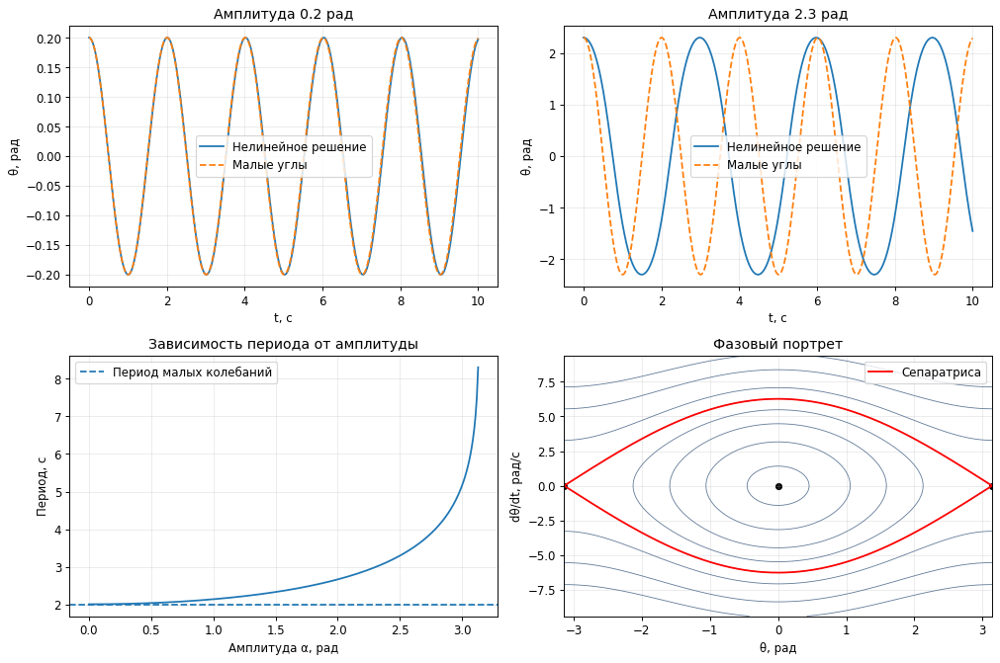

Линейный период: 2.0060666807 с
α=0.2: T=2.0110933707 с
α=2.3: T=2.9883659586 с
α=3.0: T=5.1580667543 с


In [10]:
# Длина маятника, частота и период приближения малых колебаний.
l=1.
omega0=np.sqrt(g/l)
Tlin=2*np.pi/omega0

# Состояние [θ, v]; его производная [v, −(g/l)sin θ] задаёт уравнение маятника.
def pendulum_rhs(t,state):
    return [state[1],-omega0**2*np.sin(state[0])]
def pendulum(t,theta0,vel0=0.):
    # Численно интегрируем от начального угла и скорости; t_eval — моменты вывода решения.
    sol=solve_ivp(pendulum_rhs,(0,float(t[-1])),[theta0,vel0],t_eval=t,rtol=2e-10,atol=2e-12,method='DOP853')
    # Проверяем успешное решение; строки sol.y — угол и угловая скорость.
    assert sol.success
    return sol.y

# Точное решение колебаний: ellipj — функции Якоби, ellipk — полный эллиптический интеграл K.
def exact_libration(t,alpha):
    k=np.sin(alpha/2)
    m=k*k
    sn,cn,dn,ph=ellipj(ellipk(m)-omega0*np.asarray(t),m)
    return np.array([2*np.arcsin(k*sn),-2*k*omega0*cn])
# Энергия, делённая на ml²: кинетическая часть v²/2 плюс потенциальная ω₀²(1−cos θ).
def energy(theta,vel):
    return .5*vel**2+omega0**2*(1-np.cos(theta))
t35=np.linspace(0,10,1800)
# Сравниваем малые колебания, большие колебания и полные обороты.
small=pendulum(t35,.2)
large=pendulum(t35,2.3)
rot=pendulum(t35,0,2.4*omega0)
# Сверяем численный ответ с точным и проверяем сохранение энергии.
for alpha,result in [(.2,small),(2.3,large)]:
    exact=exact_libration(t35,alpha)
    check_close(result,exact,atol=2e-8)
    assert np.max(abs(energy(*result)-energy(*result[:,0])))<2e-7
assert np.max(abs(energy(*rot)-energy(*rot[:,0])))<2e-7
# Точное вращательное решение для выбранной начальной скорости.
e=(2.4*omega0)**2/(4*omega0**2)
sn,cn,dn,am=ellipj(omega0*np.sqrt(e)*t35,1/e)
check_close(rot[0],2*am,atol=2e-8)
check_close(rot[1],2*omega0*np.sqrt(e)*dn,atol=2e-8)
fig,axes=plt.subplots(2,2,figsize=(12,8))
for ax,alpha,result in zip(axes[0],[.2,2.3],[small,large]):
    ax.plot(t35,result[0],label='Нелинейное решение')
    ax.plot(t35,alpha*np.cos(omega0*t35),'--',label='Малые углы')
    ax.set(title=f'Амплитуда {alpha} рад',xlabel='t, с',ylabel='θ, рад')
    ax.legend()
# Точный период 4K(sin²(α/2))/ω₀ зависит от амплитуды α.
alphas=np.linspace(.001,np.pi-.012,300)
periods=4*ellipk(np.sin(alphas/2)**2)/omega0
axes[1,0].plot(alphas,periods)
axes[1,0].axhline(Tlin,ls='--',label='Период малых колебаний')
axes[1,0].set(xlabel='Амплитуда α, рад',ylabel='Период, с',title='Зависимость периода от амплитуды')
axes[1,0].legend()
th=np.linspace(-np.pi,np.pi,250)
vv=np.linspace(-3*omega0,3*omega0,250)
TH,VV=np.meshgrid(th,vv)
# Фазовый портрет: линии постоянной энергии в координатах (угол, угловая скорость).
axes[1,1].contour(TH,VV,energy(TH,VV),levels=[1,5,10,15,2*omega0**2,25,35,45],colors='#607997',linewidths=.7)
# Сепаратриса — граница между колебаниями и полными оборотами.
axes[1,1].plot(th,2*omega0*np.cos(th/2),'r',label='Сепаратриса')
axes[1,1].plot(th,-2*omega0*np.cos(th/2),'r')
axes[1,1].scatter([0,-np.pi,np.pi],[0,0,0],s=25,color='black')
axes[1,1].set(xlabel='θ, рад',ylabel='dθ/dt, рад/с',title='Фазовый портрет')
axes[1,1].legend()
finish(fig)
print(f'Линейный период: {Tlin:.10f} с')
for alpha in [.2,2.3,3.]:
    print(f'α={alpha}: T={4*ellipk(np.sin(alpha/2)**2)/omega0:.10f} с')

In [11]:
t_anim=np.linspace(0,6,FRAMES)
# Заранее вычисляем три режима маятника на сетке кадров.
states=[pendulum(t_anim,.2),pendulum(t_anim,2.3),pendulum(t_anim,0,2.4*omega0)]
fig,axes=plt.subplots(2,3,figsize=(11,7))
anim_items=[]
# Верхний ряд — маятники, нижний — их движение на фазовой плоскости.
for j,(state,title) in enumerate(zip(states,['Малые колебания','Большие колебания','Вращение'])):
    ax=axes[0,j]
    ax.set(xlim=(-1.2,1.2),ylim=(-1.25,1.25),title=title,xlabel='x/l',ylabel='y/l')
    ax.set_aspect('equal')
    rod,=ax.plot([],[],'o-',lw=2,color='#316d9d')
    ghost,=ax.plot([],[],'--',color='#b9b9b9',lw=1.5)
    ax.scatter([0],[0],color='black',s=18)
    lab=ax.text(.02,.98,'',transform=ax.transAxes,va='top',fontsize=8)
    ap=axes[1,j]
    ap.set(xlim=(-np.pi,np.pi),ylim=(-3*omega0,3*omega0),xlabel='θ mod 2π',ylabel='dθ/dt')
    ap.plot(th,2*omega0*np.cos(th/2),'r--',lw=.7)
    ap.plot(th,-2*omega0*np.cos(th/2),'r--',lw=.7)
    path,=ap.plot([],[],lw=1)
    dot,=ap.plot([],[],'ro',ms=4)
    anim_items.append((rod,ghost,lab,path,dot))
fig.tight_layout()
def update35(k):
    for j,(state,items) in enumerate(zip(states,anim_items)):
        # Берём угол и скорость текущего кадра; state[:,k] выбирает весь столбец k.
        rod,ghost,lab,path,dot=items
        theta,vel=state[:,k]
        # Переводим угол в координаты конца маятника: x/l=sin θ, y/l=−cos θ.
        rod.set_data([0,np.sin(theta)],[0,-np.cos(theta)])
        # Серая линия показывает приближение малых углов θ≈αcos(ω₀t).
        if j<2:
            linear=[.2,2.3][j]*np.cos(omega0*t_anim[k])
            ghost.set_data([0,np.sin(linear)],[0,-np.cos(linear)])
        # Остаток % 2π сводит угол к диапазону [−π, π), удобному для фазового портрета.
        wrapped=(state[0,:k+1]+np.pi)%(2*np.pi)-np.pi
        plot_theta=wrapped.copy()
        # NaN разрывает линию на скачке угла от π к −π, чтобы не соединять края графика.
        if len(plot_theta)>1:
            plot_theta[1:][abs(np.diff(wrapped))>np.pi]=np.nan
        path.set_data(plot_theta,state[1,:k+1])
        dot.set_data([wrapped[-1]],[vel])
        lab.set_text(f't={t_anim[k]:.2f} с\nθ={theta:.2f} рад; ω={vel:.2f} рад/с')
movie35=movie(fig,update35)

In [12]:
assert all('frames' in html for html in [movie31,movie32,movie33,movie34,movie35])
print('Проверки пройдены.')

Проверки пройдены.
